In [1]:
import os
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..')
pth_in = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', name)
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', name)

In [3]:
# load processed data from h5ad file
fn = os.path.join(pth_in, 'processed.h5ad')
adata = sc.read_h5ad(fn); adata

AnnData object with n_obs × n_vars = 2356 × 20435
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype', 'leiden'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'source_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

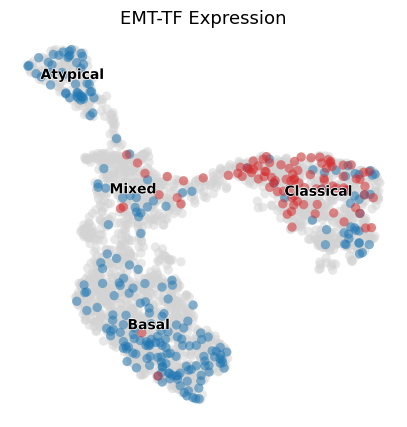

In [4]:
g_plt = {'SNAI1'  : ('tab:blue', 0),
         'ZEB1'   : ('tab:red', 4.5)}

# save EMT-TF expression figure
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, size = 180, alpha = .5,
           frameon = False, show = False,
           ax = ax)
for var, (c, thresh) in g_plt.items():
    adata_plt = adata[adata[:, var].X > thresh].copy()
    sc.pl.umap(adata_plt, na_color = c, size = 180,
               alpha = .5, frameon = False, show = False,
               ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 180,
           alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False,
           show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('EMT-TF Expression', size = 13)
fn = os.path.join(pth_out, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight')